# NMR matching task (work copy)
Match molecules A/B/C to spectra via Trotterized NMR simulation.

In [12]:
from struqture_py.spins import PauliHamiltonian
from qiskit.quantum_info.operators import SparsePauliOp
from qiskit.circuit import QuantumCircuit
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter

# NEW imports for Qiskit 2.2.x
from qiskit.primitives import StatevectorEstimator as Estimator

import matplotlib.pyplot as plt
from itertools import product
import json
import numpy as np
from pathlib import Path
import pickle
from typing import Tuple, Any
import re

## 1. Load Hamiltonian

In [13]:
# Folder that contains the Hamiltonian JSON files.
data_dir = Path("files")

# Name of the molecule.
molecule_name = "molecule A"  

# Magnetic field
field_T = 11.7433

# Build full filename.
filename = data_dir / f"{molecule_name}_B{field_T}T.json"

# Open JSON file.
with open(filename, "r") as json_file:
    hamiltonian_json = json.load(json_file)

# Create PauliHamiltonian from JSON file.
hamiltonian_struqture = PauliHamiltonian.from_json(hamiltonian_json)

# Get the number of spins in the Hamiltonian.
number_spins = hamiltonian_struqture.current_number_spins()

# Note that the energies are orders of magnitude larger than the couplings.
print("Struqture Hamiltonian:\n", hamiltonian_struqture)

Struqture Hamiltonian:
 PauliHamiltonian{
0Z: -1.5708053977817934e9,
1Z: -1.570805680525128e9,
2Z: -1.5708049108349397e9,
0X1X: 1.413716694115407e0,
0Y1Y: 1.413716694115407e0,
0Z1Z: 1.413716694115407e0,
0X2X: 1.853539665617978e1,
0Y2Y: 1.853539665617978e1,
0Z2Z: 1.853539665617978e1,
1X2X: 2.8117254249628648e1,
1Y2Y: 2.8117254249628648e1,
1Z2Z: 2.8117254249628648e1,
}


## 2. Rotating frame (subtract mean Z)

In [14]:
# We are now extracting the single-qubit Z terms from the full Hamiltonian:
z_terms = []
for i in range(number_spins):
    z_terms.append(hamiltonian_struqture.get(f"{i}Z"))

# Mean of Z terms.
mean_z_parameter = np.mean(z_terms)

# Setting the chemical shift due to rotating frame of the QC calculation:
chemical_shift_hz = mean_z_parameter

# We now subtract the mean value of the Z coupling from the full Hamiltonian
# to arrive at the Hamiltonian that is used in the NMR calculation and store the second
# chemical shift we need to apply to the spectrum at the end.
correction_hamiltonian = PauliHamiltonian()
for i in range(number_spins):
    correction_hamiltonian.set(f"{i}Z", mean_z_parameter)

hamiltonian_struqture = hamiltonian_struqture - correction_hamiltonian

# In the rotating frame, the energies are all of order 1.
print("Hamiltonian in rotating frame: \n", hamiltonian_struqture)

Hamiltonian in rotating frame: 
 PauliHamiltonian{
0Z: -6.806783962249756e1,
1Z: -3.508111741542816e2,
2Z: 4.1887901401519775e2,
0X1X: 1.413716694115407e0,
0Y1Y: 1.413716694115407e0,
0Z1Z: 1.413716694115407e0,
0X2X: 1.853539665617978e1,
0Y2Y: 1.853539665617978e1,
0Z2Z: 1.853539665617978e1,
1X2X: 2.8117254249628648e1,
1Y2Y: 2.8117254249628648e1,
1Z2Z: 2.8117254249628648e1,
}


## 3. Struqture -> Qiskit

In [15]:
def struqture_hamiltonian_to_qiskit_op(
    ham_struqture: PauliHamiltonian,
    n_qubits: int,
    reverse_qubit_order: bool = True,
) -> SparsePauliOp:
    """
    Convert struqture PauliHamiltonian keys like '0Z', '10X11X' into Qiskit labels.

    Args:
        ham_struqture (PauliHamiltonian): struqture Hamiltonian to transform to Qiskit
        n_qubits (int): number of qubits in the Hamiltonian
        reverse_qubit_order (bool): makes Qiskit's rightmost char qubit 0 (little-endian).
    """
    labels = []
    coeffs = []
    token_re = re.compile(r"(\d+)([XYZ])")

    for key, val in zip(ham_struqture.keys(), ham_struqture.values()):
        s = str(key)  # e.g., '0Z', '0X1X', '10X11X'
        pauli = ["I"] * n_qubits
        if s != "I":
            for m in token_re.finditer(s):
                idx = int(m.group(1))  # site index (can be multi-digit)
                op = m.group(2)  # 'X', 'Y', or 'Z'
                q = (n_qubits - 1 - idx) if reverse_qubit_order else idx
                if not (0 <= q < n_qubits):
                    raise IndexError(
                        f"Site index {idx} (mapped to qubit {q}) out of range 0..{n_qubits-1}"
                    )
                pauli[q] = op
        labels.append("".join(pauli))
        coeffs.append(complex(val))

    return SparsePauliOp(labels, coeffs)

In [16]:
hamiltonian_qiskit = struqture_hamiltonian_to_qiskit_op(hamiltonian_struqture, number_spins)

# Qiskit representation of the Hamiltonian.
print("Hamiltonian in Qiskit:\n", hamiltonian_qiskit)

Hamiltonian in Qiskit:
 SparsePauliOp(['IIZ', 'IZI', 'ZII', 'IXX', 'IYY', 'IZZ', 'XIX', 'YIY', 'ZIZ', 'XXI', 'YYI', 'ZZI'],
              coeffs=[ -68.06783962+0.j, -350.81117415+0.j,  418.87901402+0.j,
    1.41371669+0.j,    1.41371669+0.j,    1.41371669+0.j,
   18.53539666+0.j,   18.53539666+0.j,   18.53539666+0.j,
   28.11725425+0.j,   28.11725425+0.j,   28.11725425+0.j])


## 4. Trotter circuit & initial states

### 4.1 Trotter circuit

In [17]:
# Default number of Trottersteps.
number_of_trottersteps = 300

# Default Trotter timestep.
trotter_timestep = 0.0025



# Trotter Circuit
trotter_step_first_order = PauliEvolutionGate(
    hamiltonian_qiskit, trotter_timestep, synthesis=LieTrotter()
)

circuit = QuantumCircuit(hamiltonian_qiskit.num_qubits)
circuit.append(trotter_step_first_order, range(hamiltonian_qiskit.num_qubits))
circuit = circuit.decompose(reps=1)

print("Trotter circuit: \n", circuit)

Trotter circuit: 
      ┌──────────────┐┌─────────────────┐┌─────────────────┐                »
q_0: ┤ Rz(-0.34034) ├┤0                ├┤0                ├─■──────────────»
     ├─────────────┬┘│  Rxx(0.0070686) ││  Ryy(0.0070686) │ │ZZ(0.0070686) »
q_1: ┤ Rz(-1.7541) ├─┤1                ├┤1                ├─■──────────────»
     └┬────────────┤ └─────────────────┘└─────────────────┘                »
q_2: ─┤ Rz(2.0944) ├───────────────────────────────────────────────────────»
      └────────────┘                                                       »
«     ┌────────────────┐┌────────────────┐                                »
«q_0: ┤0               ├┤0               ├─■──────────────────────────────»
«     │                ││                │ │             ┌───────────────┐»
«q_1: ┤  Rxx(0.092677) ├┤  Ryy(0.092677) ├─┼─────────────┤0              ├»
«     │                ││                │ │ZZ(0.092677) │  Rxx(0.14059) │»
«q_2: ┤1               ├┤1               ├─■─────────────┤1   

### 4.2 TODO: initial states (X-basis product states)

In [18]:
from qiskit.circuit import ParameterVector


def xsum_eigenstate_template(n_qubits: int):
    """Parameterized prep for any eigenstate of sum_i X_i."""
    phi = ParameterVector("phi", n_qubits)
    qc = QuantumCircuit(n_qubits, name="XsumEigen")

    # TODO: add your state-preparation here that makes each qubit an X-eigensta
    # Example of parametrized dummy initial state.
    for q in range(n_qubits):
        qc.h(q)
        qc.rz(phi[q], q)

    return qc, phi


# Create the parametrized circuit.
qc_init_template, phi = xsum_eigenstate_template(number_spins)

# --- Enumerate initial states and build parameter maps ---
# TODO:
# 1) Replace the placeholder 'bits_list' below with ALL X-basis product states:
# 2) Create 'param_maps' that binds when running the circuits.

# Placeholder so the notebook runs; currently uses only the "all-plus" state.
bits_list = list(product((0, 1), repeat=number_spins))

# Placeholder parameter maps; currently binds all phi[i] to 0.0 (|+>)
param_maps = [{phi[i]: np.pi * b for i, b in enumerate(bits)} for bits in bits_list]

## 5. Simulation (Estimator)

### 5.1 Observables

In [19]:
obs_x = SparsePauliOp.from_sparse_list(
    [("X", [i], 1.0) for i in range(number_spins)], num_qubits=number_spins
)
obs_y = SparsePauliOp.from_sparse_list(
    [("Y", [i], 1.0) for i in range(number_spins)], num_qubits=number_spins
)

### 5.2 Run & collect expectation values

In [20]:
# Prebuild the parametric circuit at each step: U^n composed after the init template.
circuits_per_step = []
c = QuantumCircuit(number_spins)
c = c.compose(qc_init_template)  # still parametric in phi
circuits_per_step.append(c)

for _ in range(1, number_of_trottersteps):
    c = c.compose(circuit)  # append one more Trotter step
    circuits_per_step.append(c)

number_of_initializations = len(bits_list)
exp_x = np.zeros((number_of_initializations, number_of_trottersteps))
exp_y = np.zeros((number_of_initializations, number_of_trottersteps))

estimator = Estimator()

# Batch all initial states for each step to minimize overhead
for k, circ in enumerate(circuits_per_step):
    pubs = []
    for m in range(number_of_initializations):
        pubs.append((circ, [obs_x, obs_y], param_maps[m]))  # pass parameter_values per pub
    job = estimator.run(pubs)
    results = job.result()  # list-like; one result per pub
    for m, res in enumerate(results):
        evs = res.data.evs  # [⟨obs_x⟩, ⟨obs_y⟩]
        exp_x[m, k] = evs[0]
        exp_y[m, k] = evs[1]

### 5.3 Correlation functions C_xx, C_yx

In [21]:
# Expectation values.
c_xx = np.zeros(number_of_trottersteps)
c_yx = np.zeros(number_of_trottersteps)

# Perform vectorized calculations
mx_0 = exp_x[:, 0]
for i in range(number_of_trottersteps):
    c_xx[i] = np.sum(mx_0 * exp_x[:, i], axis=0)
    c_yx[i] = np.sum(mx_0 * exp_y[:, i], axis=0)

# --- apply a single exponential window before FFT ---
noise_strength = 5.0  # s^-1 (choose per system/step size)
times = np.arange(number_of_trottersteps) * trotter_timestep
window = np.exp(-noise_strength * times)
c_xx = c_xx * window
c_yx = c_yx * window

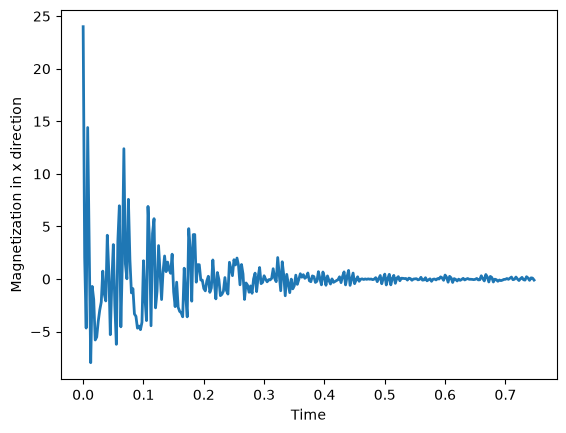

In [22]:
plt.figure(dpi=100)
plt.plot(times, c_xx, color="C0", lw=2.0)
plt.xlabel("Time", fontsize=10)
plt.ylabel("Magnetization in x direction", fontsize=10)
plt.show()

## 6. Spectrum (FFT)

In [23]:
def time_signal_to_spectrum(
    c_xx: np.ndarray,
    c_yx: np.ndarray,
    trotter_timestep: float,
    number_of_trottersteps: int,
    Hz_to_ppm_conversion: float,
    chem_shift_hz: float,
) -> Tuple[np.ndarray[Any, Any], np.ndarray[Any, Any]]:
    """Calculate the full spectrum from the computed expectation values via a Fourier Transform.

    Args:
        m_avg_z (np.ndarray): The first expectation value (c_xx)
        m_avg_y (np.ndarray): The second expectation value (c_yx)
        N_max (int): Number of Trotter steps.
        trotter_timestep (float): The Trotter timestep.
        Hz_to_ppm_conversion (float): Conversion factor from frequency to ppm.
        chem_shift_hz (float): The chemical shift of the input Hamiltonian (in Hz).

    Returns:
        Tuple[np.ndarray, np.ndarray]: A tuple containing:
            - **spectrum_full (np.ndarray):** The calculated spectrum.
            - **ppm (np.ndarray):** The ppm array to plot the full spectrum against.
    """
    spectrum_full = np.zeros(c_xx.shape[0], dtype=np.float64)

    m_avg_z = fft_causal(c_xx)
    m_avg_y = fft_causal(c_yx)

    frequencies = np.fft.fftshift(np.fft.fftfreq(number_of_trottersteps, d=trotter_timestep))

    # And now we have the frequency axis in ppm:
    # we need to shift the frequencies by twice the chemical input shift and then by the reference
    # energy, i.e. the energy of the honomuclear isotope (H) times the magnetic field.
    
    # the chemical shift:
    chem_shift = 2 * chem_shift_hz / (2.0*np.pi/Hz_to_ppm_conversion) + 1e6

    # to have the frequency axis in ppm:
    ppm = (frequencies) * Hz_to_ppm_conversion - chem_shift

    spectrum_full = m_avg_z.real + m_avg_y.imag

    spectrum_full /= np.max(np.abs(spectrum_full))

    return np.abs(spectrum_full), ppm


def fft_causal(f: np.ndarray) -> np.ndarray:
    """
    Performs the Fourier Transform of a causal signal by separating its even and odd parts.

    Args:
        f (np.ndarray): Input causal signal.

    Returns:
        np.ndarray: The complex Fourier Transform of the causal signal.
    """
    L = len(f)

    # Even part (symmetrize)
    fe = np.zeros(2 * L - 1, dtype=f.dtype)
    fe[:L] = f
    fe[L:] = f[:-1][::-1]
    fe /= 2

    # Odd part (antisymmetrize)
    fo = np.zeros(2 * L - 1, dtype=f.dtype)
    fo[:L] = f
    fo[L:] = -f[:-1][::-1]
    fo /= 2
    fo[0] = 0  # Avoids jump discontinuity at t=0

    # FFT with orthogonal normalization and shift
    fft_even = np.fft.fftshift(np.fft.fft(fe, norm="ortho"))
    fft_odd = np.fft.fftshift(np.fft.fft(fo, norm="ortho"))

    # Combine and downsample to original length
    combined_fft = (fft_even + fft_odd)[::2]

    return combined_fft

In [24]:
# Gyromagnetic ratio for 1H.
GYROMAGNETIC_RATIO_1H_RAD_S_T = 267_522_128.0

# Larmor/reference frequency in Hz at the given field.
reference_energy_hz = GYROMAGNETIC_RATIO_1H_RAD_S_T * field_T / (2 * np.pi)

# Conversion factor to go from Hz to ppm at this field: ppm = (Hz) * (1e6 / v0)
Hz_to_ppm_conversion = 1e6 / reference_energy_hz

In [25]:
spectrum_full, ppm = time_signal_to_spectrum(
    c_xx,
    c_yx,
    trotter_timestep,
    number_of_trottersteps,
    Hz_to_ppm_conversion=Hz_to_ppm_conversion,
    chem_shift_hz=chemical_shift_hz,
)

### 6.1 Reference spectrum

In [26]:
with open(data_dir / f"spectrum_3.pkl", "rb") as f:
    hqs_spectrum_tools_results = pickle.load(f)

hqs_spectrum_tools_ppm = hqs_spectrum_tools_results["frequencies"]
hqs_spectrum_tools_spectrum = hqs_spectrum_tools_results["spectrum"]
hqs_spectrum_tools_spectrum /= np.max(np.abs(hqs_spectrum_tools_spectrum))

## 7. Matching task

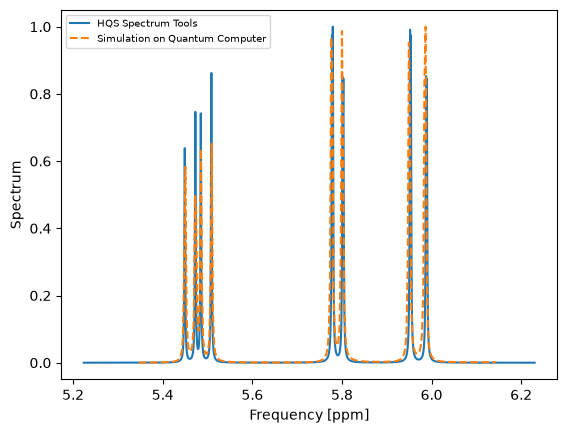

In [27]:
plt.figure(dpi=100)
plt.plot(
    hqs_spectrum_tools_ppm, hqs_spectrum_tools_spectrum, color="C0", label="HQS Spectrum Tools"
)
plt.plot(ppm, spectrum_full, color="C1", ls="--", label="Simulation on Quantum Computer")

plt.xlabel("Frequency [ppm]")
plt.ylabel("Spectrum")
plt.legend(fontsize=7)
plt.show()

## 8. Noise tolerance sweep